> ### Note on Labs and Assignments:
>
> 🔧 Look for the **wrench emoji** 🔧 — it highlights where you're expected to take action!
>
> These sections are graded and are not optional.
>

# IS 4487 Lab 13: Sentiment Analysis

## Outline

- Analyze a dataset utilizing sentiment
- Compare the VADER and TextBlob models
- Learn the basics of sentiment analysis

In this lab, you will explore **sentiment analysis** techniques to determine the positivity/negativity of certain sentences.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Labs/lab_13_text_analytics.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Movie Review: Business Context

We will use a dataset containing movie reviews.  Each review is contained in the "Phrase" variable.  This dataset is pre-labeled with the Sentiment, but we will use tools to calculate our own Sentiment, which could then be compared to the pre-labeled values.  

The dataset does not specify the movie that it is reviewing.  We wouldn't be able to use this to calculate a movie score, like Rotten Tomatoes.  But we can observe the overall sentiment of reviewers and practice using the text analytics tools available in Python.

## Data Dictionary

| Column                        | Data Type       | Description                                                  |
|------------------------------|------------------|--------------------------------------------------------------|
| `PhraseID`                   | Integer           | ID of an entry                                               |
| `SentenceID`                 | Integer           | Shows which phrases belong to which sentence                                      |
| `Phrase`             | String       | A sentence/phrase                       |
| `Sentiment`                 | Categorical       | 0 = Very Negative, 1 = Negative, 2 = Neutral, 3 = Positive, 4= Highly Positive        |

Source: https://www.kaggle.com/datasets/satwikdondapati/moviereviewsentimentalanalysis

## Part 1: Load and Prepare the Data

### What you are going to do:
- Load the dataset
- Preview the data

### Why this matters:
All throughout the semester you've mainly dealt with data that had a wide variety of types. But what if we only have a few variables and one of them has lots of text?

**Things to notice:**
- Which variables are actually important?
- Why are there so few variables? Which variable(s) has the most data?


### 🔧 Do the following
Import the libraries and dataset

In [2]:
import nltk
nltk.download('vader_lexicon')

from nltk.sentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import pandas as pd
import csv

url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/movie_reviews.tsv"
df = pd.read_csv(url, sep='\t', quoting=csv.QUOTE_MINIMAL)

df.head()


[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


,PhraseId,SentenceId,Phrase,Sentiment
0,1,1,A series of escapades demonstrating the adage ...,1
1,2,1,A series of escapades demonstrating the adage ...,2
2,3,1,A series,2
3,4,1,A,2
4,5,1,series,2


In [3]:
# Load the reviews
url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/refs/heads/main/DataSets/movie_reviews.tsv"
df = pd.read_csv(url, sep='\t', quoting=csv.QUOTE_MINIMAL)

df.head()

,PhraseId,SentenceId,Phrase,Sentiment
0,1,1,A series of escapades demonstrating the adage ...,1
1,2,1,A series of escapades demonstrating the adage ...,2
2,3,1,A series,2
3,4,1,A,2
4,5,1,series,2


In [4]:
#Check the dataframe characteristics
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156060 entries, 0 to 156059
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   PhraseId    156060 non-null  int64 
 1   SentenceId  156060 non-null  int64 
 2   Phrase      156060 non-null  object
 3   Sentiment   156060 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 4.8+ MB


# Part 2 : See the Scores
### What you are going to do:
- count how many entries belong to each Sentiment score
- create a visualization of the value counts

### Why this matters:
In the dataset you'll notice that each phrase has a sentiment score. These scores tell us whether a phrase is positive or negative or neutral in tone. In later steps we will be predicting scores, so it is important to know if there is any skew of sentiment within the data.  

**Things to notice:**
- Why are there 5 total Sentiment scores?
- What does each score mean?
- What is the count of each score?

### 🔧 Do the following — Part 2

1. create a variable that stores the ```value_counts``` of the Sentiment column
2. create a bar chart using the ```value_counts``` variable you just created

Sentiment
0     7072
1    27273
2    79582
3    32927
4     9206
Name: count, dtype: int64


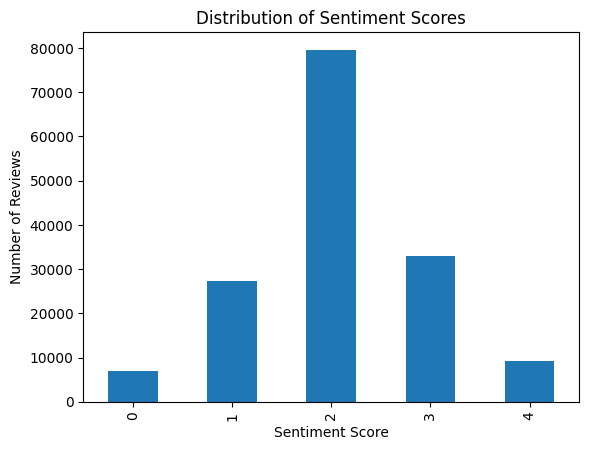

In [5]:
sentiment_counts = df['Sentiment'].value_counts().sort_index()

print(sentiment_counts)

sentiment_counts.plot(kind='bar')
plt.xlabel('Sentiment Score')
plt.ylabel('Number of Reviews')
plt.title('Distribution of Sentiment Scores')
plt.show()


### Reflection:
1. make a comment about the chart. Is there any skew within the data? Is it more positive, negative, or neutral? (Hint: refer to the data dictionary at the very top)

### ✍️ Your Response: 🔧
1. There's not really much of a skew within the data, it's much more neutral and roughly symmetric.

# Part 3: VADER
### What you are going to do:
- run and train a VADER model
- evaluate its performance

### Why this matters:
Sentiment analysis matters for a business because it helps them understand how customers feel about their products, services, or brand by analyzing large amounts of text data like reviews, social media posts, and comments. By identifying positive or negative sentiment at scale, companies can respond to customer concerns, improve their offerings, and make more informed decisions about marketing, customer experience, and overall strategy.

### How VADER Works
VADER (Valence Aware Dictionary and sEntiment Reasoner) is a rule-based sentiment analysis tool that uses a predefined list (lexicon) of words with associated sentiment scores, along with rules that account for things like capitalization, punctuation, and intensifiers (e.g., “very” or “extremely”). It combines these factors to produce an overall sentiment score indicating whether text is positive, negative, or neutral.

Since it looks at one word at a time it may struggle with longer sentences. So VADER is best suited for analyzing social media and reviews.

**Things to notice:**
- what does the score_to_label function do?

In [6]:
# set up and run the VADER model
sia = SentimentIntensityAnalyzer()

df["vader_score"] = [sia.polarity_scores(text)["compound"] for text in df["Phrase"]]

# there are a total of 5 sentiment scores but polarity only gives us scores between -1 to 1
# need to map the scores from the dataset so that polarity can use it
def score_to_label(score):
    if score <= -0.6:
        return 0  # very negative
    elif score <= -0.2:
        return 1  # somewhat negative
    elif score < 0.2:
        return 2  # neutral
    elif score < 0.6:
        return 3  # somewhat positive
    else:
        return 4  # very positive

df["vader_pred"] = df["vader_score"].apply(score_to_label)

# View the predicted score
df.head()

,PhraseId,SentenceId,Phrase,Sentiment,vader_score,vader_pred
0,1,1,A series of escapades demonstrating the adage ...,1,0.5579,3
1,2,1,A series of escapades demonstrating the adage ...,2,0.4404,3
2,3,1,A series,2,0.0000,2
3,4,1,A,2,0.0000,2
4,5,1,series,2,0.0000,2


### 🔧 Do the following — Part 3
Now we know if the data is positively, negatively, or neutrally skewed. For the next two steps we are going to be testing out 2 new models and comparing their results.
1. using ```vader_pred``` and ```Sentiment``` generate a classification report
2. using ```vader_pred``` and ```Sentiment``` generate a confusion matrix

In [7]:
print(classification_report(df['Sentiment'], df['vader_pred']))
print(confusion_matrix(df['Sentiment'], df['vader_pred']))
print("VADER Accuracy:", accuracy_score(df['Sentiment'], df['vader_pred']))


              precision    recall  f1-score   support

           0       0.22      0.14      0.17      7072
           1       0.38      0.26      0.31     27273
           2       0.65      0.74      0.69     79582
           3       0.40      0.38      0.39     32927
           4       0.27      0.33      0.30      9206

    accuracy                           0.53    156060
   macro avg       0.38      0.37      0.37    156060
weighted avg       0.51      0.53      0.51    156060

[[ 1016  2433  2530   831   262]
 [ 1580  7043 13802  3840  1008]
 [ 1483  6983 58897 10144  2075]
 [  461  1757 13627 12373  4709]
 [   69   302  2092  3737  3006]]
VADER Accuracy: 0.5275855440215301


### Reflection:
1. make a comment. Why are the values for a sentiment score of 2 much higher than all the others?

### ✍️ Your Response: 🔧
1. For VADER, I see that values for a sentiment score of 2 are much higher than all of the others because the dataset has mostly neutral reviews and it doesn't do well with extreme values positive or negative.

# Part 4: TextBlob
### What you are going to do:
- evaluate the performance of a TextBlob model

## How TextBlob Works:
Unlike VADER, TextBlod utilizes tokenization to determine the sentiment of a phrase. Tokenization is great for breaking up large sentences and paragraphs. Because of this, TextBlob works better on longer sentences and is best suited for analyzing longer text documents such as articles or blogs.

Tokenization is the process of breaking text into smaller pieces called tokens, which are usually words, phrases, or sentences. For example, the sentence “Loved the movie!” might be split into tokens like ["loved", "the", "movie", "!"]. This step is important because computers need text to be structured in smaller units before they can analyze it—whether for tasks like counting words, understanding meaning, or performing sentiment analysis.

**Things to notice:**
- how does accuracy compare to the previous model?

In [9]:
# set up and run the textblob model
df["textblob_score"] = [TextBlob(text).sentiment.polarity for text in df["Phrase"]]
df["textblob_pred"] = df["textblob_score"].apply(score_to_label)

# View the predicted score
df.head()

,PhraseId,SentenceId,Phrase,Sentiment,vader_score,vader_pred,textblob_score,textblob_pred
0,1,1,A series of escapades demonstrating the adage ...,1,0.5579,3,0.4,3
1,2,1,A series of escapades demonstrating the adage ...,2,0.4404,3,0.7,4
2,3,1,A series,2,0.0000,2,0.0,2
3,4,1,A,2,0.0000,2,0.0,2
4,5,1,series,2,0.0000,2,0.0,2


### 🔧 Do the following — Part 4
Now let's evaluate the TextBlob model.
1. using ```textblob_pred``` and ```Sentiment``` generate a classification report
2. using ```textblob_pred``` and ```Sentiment``` generate a confusion matrix

#### Note on Evaluation

In this lab, VADER and TextBlob are pre-trained, rule-based models. We are applying them directly to the full dataset without training.

Because of this, the evaluation metrics reflect performance on this dataset only, not on unseen data. This is acceptable here since we are exploring baseline sentiment tools rather than building predictive models.

In [10]:
print(classification_report(df['Sentiment'], df['textblob_pred']))
print(confusion_matrix(df['Sentiment'], df['textblob_pred']))
print("TextBlob Accuracy:", accuracy_score(df['Sentiment'], df['textblob_pred']))


              precision    recall  f1-score   support

           0       0.25      0.11      0.15      7072
           1       0.38      0.16      0.22     27273
           2       0.60      0.81      0.69     79582
           3       0.38      0.31      0.34     32927
           4       0.25      0.19      0.21      9206

    accuracy                           0.52    156060
   macro avg       0.37      0.31      0.32    156060
weighted avg       0.48      0.52      0.48    156060

[[  748  1746  3763   718    97]
 [ 1184  4289 17860  3467   473]
 [  918  3908 64760  8472  1524]
 [  183  1262 18253 10271  2958]
 [   17   195  3199  4083  1712]]
TextBlob Accuracy: 0.5240292195309496


### Reflection:
1. Make a comment. Why are the values for a sentiment score of 2 much higher than all the others?

### ✍️ Your Response: 🔧
1. For TextBlob, I see that the values for a sentiment score of 2 are much higher than all of the others because most of the reviews are neutral and has trouble with positive and negative reviews too.


## 🔧 Part 5: Reflection (100 words or less)

In this lab you built a VADER and TextBlob model and evaluated their results. You also learned about some of the pros and cons of each model and in which situations they would be used.

Use the cell below to answer the following questions:

1. In the dataset there was a certain sentiment score that had an extremely high frequency. How did the high number of frequency for this score affect its associated metrics?
1. Which model had better accuracy in this lab? Why is that the case? (Hint: look at the results of head() at the very top of this lab. How long are the phrases in this dataset?)
2. Why is it important for a business to determine sentiment? How could a business use sentiment analysis and customer reviews to improve customer service?

### ✍️ Your Response: 🔧
1. It was clear that sentiment score 2 which is neutral had an extremely high frequency. Since there were so many neutral reviews, both of the models reacted the same way, resulting in a higher metric in that category.

2. I noticed that VADER barely had a higher accuracy of 52.76% whereas Textblob was 52.40%. I think VADER was higher because the dataset had shorter text which could've made it slightly more accurate.

3. It's important for a business to determine sentiment because it helps us understand how customers feel about the product or service. If we can figure out the issue or any areas to improve, it would make our business more sucessful.

# Export Your Notebook to Submit in Canvas
Use the instructions from Lab 1

In [ ]:
!jupyter nbconvert --to html "lab_13_text_analytics.ipynb"